# Sensibilidad del EKF a las varianzas cinéticas

Se reproduce el EKF del [notebook 09](09_ekf_lima_clean_figures.source.ipynb), con acumulador y medias causales de CO₂ de 30 minutos. Cada barrido multiplica una entrada diagonal de \(D_\theta\), o las tres juntas, por 0, 0,25, 0,5, 1, 2 o 4. El factor 1 corresponde al EKF original.

Todas las ejecuciones usan los mismos parámetros cinéticos nominales, las condiciones iniciales y \(P_0\) de cada lote, \(R=0{,}00218\), las entradas y las ventanas asimiladas. \(Q_k=G_kD_\theta G_k^\top\) se calcula en cada paso sobre la trayectoria del escenario. Un factor cero elimina el aporte de la fuente a \(Q_k\).

Se compara el RMSE de la estimación de biomasa viable y YAN frente a las muestras de cada lote, con los criterios del notebook 09. LAB016–018 aportan muestras de biomasa. El YAN se evalúa con las muestras posteriores al inicio de LAB019–021. Los factores son escenarios de sensibilidad.

In [1]:
from pathlib import Path
import ast
import json
import os
import sys
from types import ModuleType

import matplotlib.pyplot as plt
import nbformat
import numpy as np
import pandas as pd
import scipy
from IPython.display import display

ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "src/wine_fermentation").is_dir())
EKF = ROOT / "notebooks/EKF"
HERE = EKF / "kalman_analysis"
prefix = Path(os.environ["CONDA_PREFIX"]).resolve()
assert prefix.name.lower() == "fermentation" and Path(sys.prefix).resolve() == prefix
print(f"Kernel {prefix.name} · SciPy {scipy.__version__}")

# Load the existing helpers as Python functions. The filter below uses the
# vectorized NumPy transition from EKF05 and does not require Numba.
core_path = HERE / "analysis_core.py"
tree = ast.parse(core_path.read_text(encoding="utf-8"))
tree.body = [node for node in tree.body
             if not (isinstance(node, ast.ImportFrom) and node.module == "numba")]
for node in tree.body:
    if isinstance(node, ast.FunctionDef):
        node.decorator_list = [
            d for d in node.decorator_list
            if not (isinstance(d, ast.Call) and isinstance(d.func, ast.Name) and d.func.id == "njit")
        ]
core = ModuleType("analysis_core")
core.__file__ = str(core_path)
exec(compile(tree, str(core_path), "exec"), vars(core))

# Reuse the six-lot input preparation from the four-source comparison.
reference = HERE / "04_gf_variable_solubility_fourth_noise_source.source.ipynb"
reference_nb = nbformat.read(reference, as_version=4)
preparation = next(cell.source for cell in reference_nb.cells
                   if cell.cell_type == "code" and "DATA,CHEM,AUDIT,_=core.prepare(ROOT)" in cell.source)
assert preparation.count("import analysis_core as core") == 1
preparation = preparation.replace("import analysis_core as core", "")
exec(compile(preparation.replace("display(AUDIT)", ""), str(reference), "exec"))

calibration = ROOT / "notebooks/diagnostics/zenteno_lab004_009_incertidumbre_exploratoria.ipynb"
saved_nb = nbformat.read(calibration, as_version=4)
saved = json.loads(saved_nb.cells[-1].outputs[-1].text)
rate_names = ["mu0", "betaG0", "betaF0"]
assert saved["orden_D_theta"] == rate_names
D_theta = np.array(saved["D_theta_Yef_fijo"], dtype=float)
np.testing.assert_array_equal(D_theta, np.diag(np.diag(D_theta)))
assert (np.diag(D_theta) > 0).all()
R = 0.00218
R_cell = next(cell.source for cell in reference_nb.cells
              if cell.cell_type == "code" and "R = 0.00218" in cell.source)
assert ast.literal_eval(ast.parse(R_cell).body[0].value) == R
theta = core.THETA
nominal = np.array([theta[name] for name in rate_names])
sigma_theta = np.sqrt(np.diag(D_theta))
SCALE = core.SCALE
scale_outer = np.outer(SCALE, SCALE)
KLA, GAIN = core.ARCHIVED_GAS
PCO2_BAR = 1.0


Kernel fermentation · SciPy 1.13.1


In [2]:
# Reuse the equations from the vectorized G/F EKF. Supply one set of three
# rate coefficients per trajectory, with the other coefficients shared.
source05 = EKF / "05_zenteno_co2_variable_solubility.source.ipynb"
nb05 = nbformat.read(source05, as_version=4)
functions = {}
for cell in nb05.cells:
    if cell.cell_type == "code":
        for node in ast.parse(cell.source).body:
            if isinstance(node, ast.FunctionDef):
                functions[node.name] = ast.get_source_segment(cell.source, node)
for name in ("co2_saturation", "gas_exchange"):
    exec(compile(functions[name], str(source05), "exec"))

rates_source = functions["rates_ekf"]
for original, replacement in (
    ("def rates_ekf(w,t,T,S0):", "def rates_ekf(w,t,T,S0,rate_coefficients):"),
    ("theta['mu0']", "rate_coefficients[:, 0]"),
    ("theta['betaG0']", "rate_coefficients[:, 1]"),
    ("theta['betaF0']", "rate_coefficients[:, 2]"),
):
    assert rates_source.count(original) == 1
    rates_source = rates_source.replace(original, replacement)
exec(compile(rates_source, str(source05), "exec"))


def transition(points, rate_coefficients, start, end, data):
    """Integrate each trajectory with its own constant rates over this interval."""
    w = points * SCALE
    n = max(1, int(np.ceil((end - start) * 60 - 1e-7)))
    dt = (end - start) / n
    available = data["available"]
    temperatures = data["temperature"]
    for j in range(n):
        t = start + j * dt
        times = np.array([t, t + dt / 2, t + dt])
        indices = np.searchsorted(available, times + 1e-12, side="right") - 1
        if indices[0] < 0:
            raise ValueError("No hay temperatura causal al comienzo del intervalo")
        T0, Tm, T1 = temperatures[indices]
        S0 = data["S0"]
        k1 = rates_ekf(w, t, T0, S0, rate_coefficients)
        k2 = rates_ekf(w + dt * k1 / 2, t + dt / 2, Tm, S0, rate_coefficients)
        k3 = rates_ekf(w + dt * k2 / 2, t + dt / 2, Tm, S0, rate_coefficients)
        k4 = rates_ekf(w + dt * k3, t + dt, T1, S0, rate_coefficients)
        w = np.maximum(w + dt * (k1 + 2 * k2 + 2 * k3 + k4) / 6, 0.)
    return w / SCALE


def sensitivities(z, start, end, data, kinetic, relative_step=1e-4):
    state_step = 1e-5
    delta = np.eye(len(z)) * state_step
    lower = z - delta * (z >= state_step)[:, None]
    denominator = state_step * (1 + (z >= state_step))
    points = np.vstack([z, z + delta, lower])
    coefficients = np.tile(nominal, (len(points), 1))
    if kinetic:
        parameter_step = relative_step * nominal
        parameter_delta = np.diag(parameter_step)
        points = np.vstack([points, np.tile(z, (6, 1))])
        coefficients = np.vstack([coefficients, nominal + parameter_delta, nominal - parameter_delta])

    predicted = transition(points, coefficients, start, end, data)
    J = ((predicted[1:8] - predicted[8:15]) / denominator[:, None]).T
    G = ((predicted[15:18] - predicted[18:21]) / (2 * parameter_step[:, None])).T if kinetic else None
    return predicted[0], J, G


# Compare with the archived scalar RHS and transition in several regimes.
data = DATA["LAB019"]
for start, state in (
    (3., [0.4, .20, 90., 95., 15., .02, 0.]),
    (31., [1.8, .12, 65., 70., 36., .65, .01]),
    (75., [2.4, .03, 27., 43., 65., 1.0, .02]),
    (120., [.9, 0., 0., 12., 94., 1.2, .03]),
):
    w = np.asarray(state)
    z = w / SCALE
    temp = core.temperature_at(start, data["available"], data["temperature"])
    np.testing.assert_allclose(
        rates_ekf(w[None, :], start, temp, data["S0"], nominal[None, :])[0],
        core.rhs(w, temp, data["S0"], KLA, GAIN), atol=1e-13, rtol=1e-12,
    )
    end = start + 1 / 12
    zp, J, G = sensitivities(z, start, end, data, True)
    z_ref, J_ref = core.jacobian(z, start, end, data["available"], data["temperature"],
                                 data["S0"], KLA, GAIN, 1 / 60)
    np.testing.assert_allclose(zp, z_ref, atol=1e-13)
    np.testing.assert_allclose(J, J_ref, atol=1e-9)
    _, _, G_fine = sensitivities(z, start, end, data, True, relative_step=5e-5)
    np.testing.assert_allclose(G, G_fine, atol=5e-7, rtol=3e-3)
print("Verificadas la dinámica nominal, las sensibilidades y el paso de diferencias finitas.")


Verificadas la dinámica nominal, las sensibilidades y el paso de diferencias finitas.


In [3]:
def replay(data, parameter_sd):
    grid = data["grid"]
    z = data["initial"] / SCALE
    P = data["P0"] / scale_outer
    states = np.empty((len(grid), len(z)))
    covariance = np.empty((len(grid), len(z), len(z)))
    diag = np.full((len(grid), 7), np.nan)
    injected = np.zeros_like(covariance)
    for i, end in enumerate(grid):
        if i:
            start = grid[i - 1]
            z, J, G = sensitivities(z, start, end, data, kinetic=True)
            # G differentiates the integrated transition for this interval.
            scaled_G = G * parameter_sd
            Q = scaled_G @ scaled_G.T
            injected[i] = Q * scale_outer
            P = J @ P @ J.T + Q
            P = (P + P.T) / 2

        z[1] += data["doses"][i] / SCALE[1]
        if end > 0 and abs(end / .5 - round(end / .5)) < 1e-8:
            predicted = z[6] / .5
            innovation = data["y"][i] - predicted
            S = 4 * P[6, 6] + R
            clips = 0
            if data["update"][i]:
                K = 2 * P[:, 6] / S
                updated = z + K * innovation
                clips = np.count_nonzero(updated[:6] < 0)
                B = np.eye(len(z))
                B[:, 6] -= 2 * K
                P = B @ P @ B.T + np.outer(K, K) * R
                P = (P + P.T) / 2
                z = np.maximum(updated, 0)
            diag[i] = [predicted, innovation, S, innovation**2 / S, clips,
                       data["update"][i], data["valid"][i]]
            z[6] = 0.
            P[6, :] = P[:, 6] = 0.
        states[i] = z * SCALE
        covariance[i] = P * scale_outer
    assert np.isfinite(states).all() and np.isfinite(covariance).all()
    assert np.linalg.eigvalsh(injected).min() > -1e-9
    np.testing.assert_array_equal(diag[:, 5] == 1, data["update"])
    return (states, covariance, diag), injected


In [4]:
FACTORS = (0., .25, .5, 1., 2., 4.)
FAMILIES = {
    "Crecimiento": (0,),
    "Fermentación de glucosa": (1,),
    "Fermentación de fructosa": (2,),
    "Las tres fuentes": (0, 1, 2),
}
base_variances = np.diag(D_theta)
scenarios = {}
for family, indices in FAMILIES.items():
    for factor in FACTORS:
        multipliers = np.ones(3)
        multipliers[list(indices)] = factor
        scenarios[family, factor] = base_variances * multipliers

variance_table = pd.DataFrame.from_dict(
    scenarios, orient="index", columns=rate_names
)
variance_table.index = pd.MultiIndex.from_tuples(variance_table.index, names=["Barrido", "Factor"])
display(variance_table.style.format("{:.6g}"))
assert len({tuple(v) for v in scenarios.values()}) == 21

In [5]:
from time import perf_counter

reference_metrics = {
    "LAB019": {"X": 0.66859, "N": 20.85265},
    "LAB020": {"X": 0.57976, "N": 18.57756},
    "LAB021": {"X": 0.93923, "N": 13.12089},
    "LAB016": {"X": 0.55198},
    "LAB017": {"X": 0.82014},
    "LAB018": {"X": 0.46678},
}
baseline_inputs = {
    lab: {key: DATA[lab][key].copy() for key in ("P0", "initial", "update", "y")}
    for lab in LABS
}
records = []
start_clock = perf_counter()
for lab in LABS:
    by_variance = {}
    for (family, factor), variances in scenarios.items():
        key = tuple(variances)
        if key not in by_variance:
            result, injected = replay(DATA[lab], parameter_sd=np.sqrt(variances))
            if factor == 0 and family == "Las tres fuentes":
                assert not injected.any()
            assert np.linalg.eigvalsh(result[1]).min() >= -1e-8
            scores, _, _ = core.diagnostics(DATA, CHEM, lab, result)
            scores = scores.loc[scores.variable.isin(["X", "N"]), ["LAB", "variable", "unit", "n", "RMSE"]]
            by_variance[key] = scores
        records.append(by_variance[key].assign(Grupo=ROLE[lab], Barrido=family, Factor=factor))
    for key, original in baseline_inputs[lab].items():
        np.testing.assert_array_equal(DATA[lab][key], original)
    print(f"{lab}: {len(by_variance)} escenarios únicos · {perf_counter()-start_clock:.1f} s acumulados", flush=True)

metrics = pd.concat(records, ignore_index=True)
reference = metrics.loc[(metrics.Barrido == "Las tres fuentes") & (metrics.Factor == 1)]
assert len(metrics) == 4 * 6 * 9 and len(reference) == 9
assert np.isfinite(metrics.RMSE).all()
assert (metrics.groupby(["LAB", "variable"]).n.nunique() == 1).all()
for row in reference.itertuples():
    np.testing.assert_allclose(row.RMSE, reference_metrics[row.LAB][row.variable], rtol=0, atol=5.1e-6)
    assert row.n == (12 if row.variable == "N" else 10 if row.Grupo == "Development" else 3)
baseline = reference[["LAB", "variable", "RMSE"]].rename(columns={"RMSE": "RMSE_base"})
metrics = metrics.merge(baseline, on=["LAB", "variable"], validate="many_to_one")
metrics["Cambio"] = metrics.RMSE - metrics.RMSE_base
assert (metrics.loc[metrics.Factor == 1, "Cambio"] == 0.).all()
print("Caso base verificado contra los nueve RMSE publicados en el notebook 09.")

LAB019: 21 escenarios únicos · 136.6 s acumulados


LAB020: 21 escenarios únicos · 286.8 s acumulados


LAB021: 21 escenarios únicos · 419.7 s acumulados


LAB016: 21 escenarios únicos · 542.3 s acumulados


LAB017: 21 escenarios únicos · 656.8 s acumulados


LAB018: 21 escenarios únicos · 770.7 s acumulados


Caso base verificado contra los nueve RMSE publicados en el notebook 09.


## RMSE por lote

Las columnas corresponden al factor aplicado a la varianza. Cada tabla indica el número de muestras puntuadas por lote. En las figuras, la línea vertical marca el factor 1.

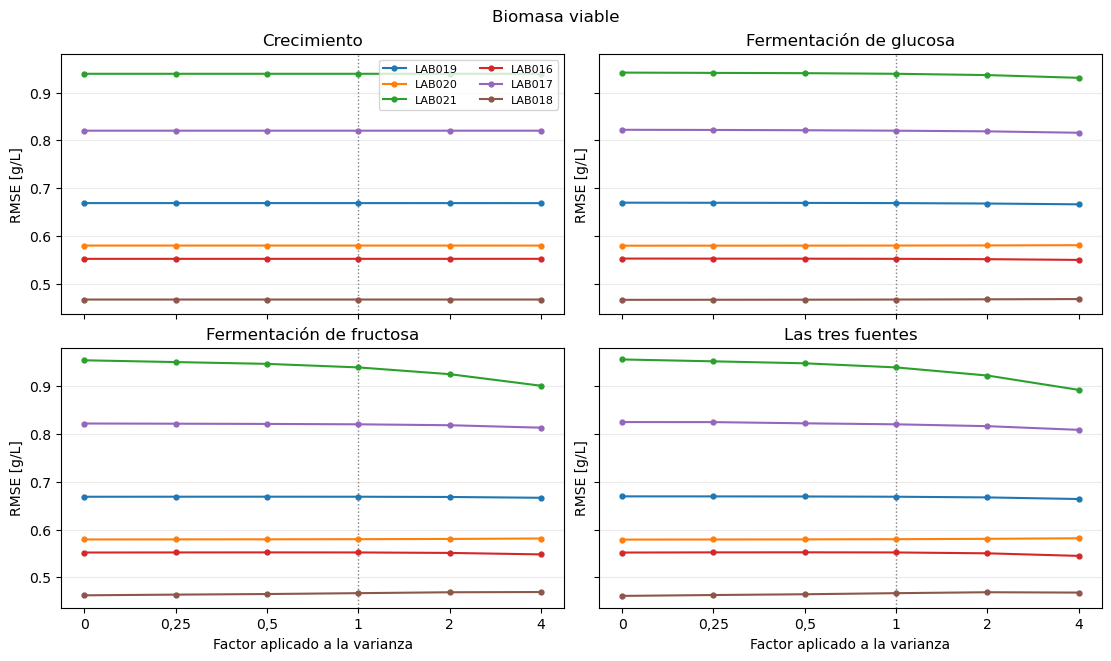

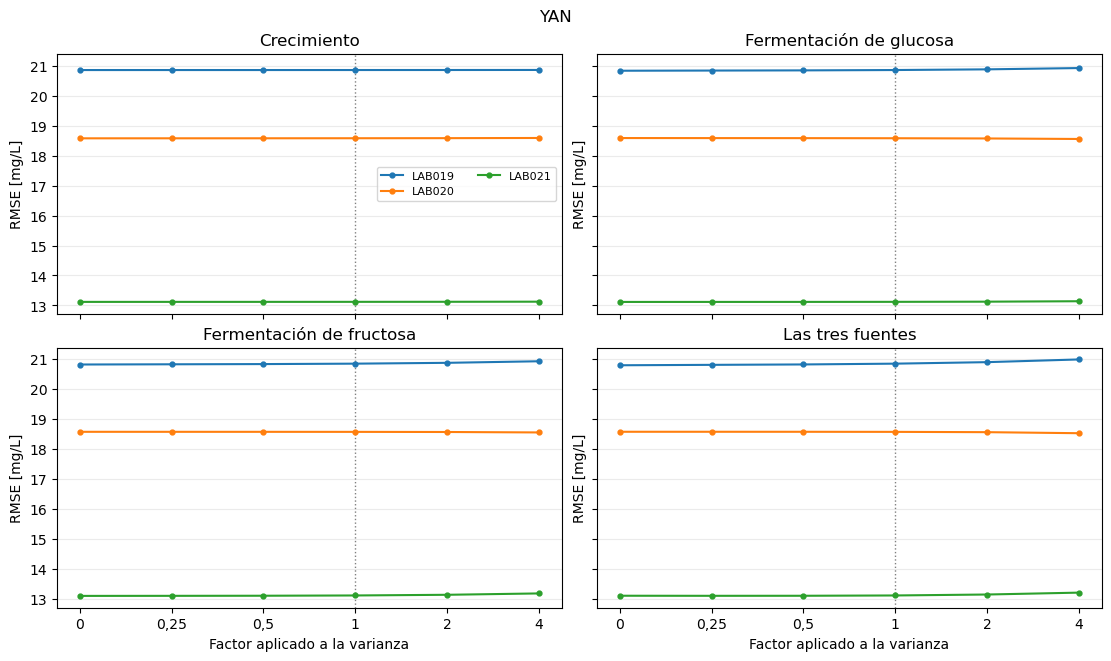

In [6]:
for variable, label, unit in (("X", "Biomasa viable", "g/L"), ("N", "YAN", "mg/L")):
    subset = metrics.loc[metrics.variable == variable]
    table = subset.pivot(index=["Barrido", "LAB", "n"], columns="Factor", values="RMSE")
    table = table.reindex(list(FAMILIES), level="Barrido").reindex(columns=FACTORS)
    display(table.style.format("{:.4f}" if variable == "X" else "{:.3f}").set_caption(f"{label} · RMSE [{unit}]"))

    fig, axes = plt.subplots(2, 2, figsize=(11, 6.5), sharex=True, sharey=True, layout="constrained")
    labels = tuple(lab for lab in LABS if lab in set(subset.LAB))
    for ax, family in zip(axes.flat, FAMILIES):
        block = subset.loc[subset.Barrido == family]
        ax.axvline(FACTORS.index(1.), color="0.5", linestyle=":", linewidth=1)
        for lab in labels:
            scores = block.loc[block.LAB == lab].set_index("Factor").reindex(FACTORS)
            ax.plot(range(len(FACTORS)), scores.RMSE, marker="o", markersize=3.5, label=lab)
        ax.set(title=family, ylabel=f"RMSE [{unit}]")
        ax.set_xticks(range(len(FACTORS)), [f"{x:g}".replace(".", ",") for x in FACTORS])
        ax.grid(axis="y", alpha=.25)
    axes[0, 0].legend(ncol=2, fontsize=8, loc="best")
    for ax in axes[1]:
        ax.set_xlabel("Factor aplicado a la varianza")
    fig.suptitle(label)
    plt.show()

## Magnitud del cambio respecto del EKF original

El máximo cambio absoluto de RMSE indica qué barrido mueve más el resultado de cada lote en el rango probado. Los cambios con signo indican cuánto se reduce o aumenta el RMSE en los escenarios explorados. Un mínimo por lote describe la sensibilidad de ese lote.

In [7]:
summary = (
    metrics.groupby(["variable", "LAB", "Barrido"], sort=False)
    .agg(RMSE_base=("RMSE_base", "first"),
         Cambio_min=("Cambio", "min"), Cambio_max=("Cambio", "max"))
    .reset_index()
)
summary["Cambio_abs_max"] = summary[["Cambio_min", "Cambio_max"]].abs().max(axis=1)
for variable, label, unit in (("X", "Biomasa viable", "g/L"), ("N", "YAN", "mg/L")):
    block = summary.loc[summary.variable == variable]
    pivot = block.pivot(index=["LAB", "RMSE_base"], columns="Barrido", values="Cambio_abs_max")
    pivot = pivot.reindex(columns=list(FAMILIES))
    display(pivot.round(4).style.format("{:.4f}").set_caption(f"{label} · Máximo cambio absoluto del RMSE [{unit}]"))

print(summary.to_string(index=False, float_format=lambda v: f"{v:.5f}"))

,Barrido,Crecimiento,Fermentación de glucosa,Fermentación de fructosa,Las tres fuentes
LAB,RMSE_base,,,,
LAB016,0.551981,0.0000,0.0023,0.0041,0.0072
LAB017,0.820135,0.0000,0.0043,0.0070,0.0116
LAB018,0.466778,0.0000,0.0010,0.0045,0.0057
LAB019,0.668592,0.0001,0.0026,0.0022,0.0048
LAB020,0.579762,0.0000,0.0008,0.0014,0.0019
LAB021,0.939233,0.0000,0.0085,0.0383,0.0471


,Barrido,Crecimiento,Fermentación de glucosa,Fermentación de fructosa,Las tres fuentes
LAB,RMSE_base,,,,
LAB019,20.852646,0.0022,0.0657,0.0795,0.1403
LAB020,18.577557,0.0087,0.0244,0.0190,0.0447
LAB021,13.120891,0.0053,0.0202,0.0679,0.0945


variable    LAB                  Barrido  RMSE_base  Cambio_min  Cambio_max  Cambio_abs_max
       X LAB019              Crecimiento    0.66859    -0.00006     0.00002         0.00006
       N LAB019              Crecimiento   20.85265    -0.00073     0.00220         0.00220
       X LAB019  Fermentación de glucosa    0.66859    -0.00255     0.00089         0.00255
       N LAB019  Fermentación de glucosa   20.85265    -0.02345     0.06568         0.06568
       X LAB019 Fermentación de fructosa    0.66859    -0.00218     0.00008         0.00218
       N LAB019 Fermentación de fructosa   20.85265    -0.02852     0.07952         0.07952
       X LAB019         Las tres fuentes    0.66859    -0.00480     0.00076         0.00480
       N LAB019         Las tres fuentes   20.85265    -0.05367     0.14027         0.14027
       X LAB020              Crecimiento    0.57976    -0.00004     0.00001         0.00004
       N LAB020              Crecimiento   18.57756    -0.00289     0.00866     